In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
#"C:\Users\mathe\Downloads\archive\Housing.csv"

In [3]:
file_path = r'C:\Users\mathe\Downloads\archive\Housing.csv' #r is there so python understands that its not code and it is a character - must for all file locations
df = pd.read_csv(file_path)
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
#displaying some statistics about the data
df.describe()
#df.columns


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [5]:
#to know what kind of datatype
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [6]:
#check for null values
df.isnull().sum() #without sum all of them is displayed

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [7]:
df['price_per_sqft'] = df["price"] / df["area"]
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,price_per_sqft
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished,1792.452830
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished,1367.187500
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished,1229.919679
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished,1628.666667
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished,1537.735849
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished,606.666667
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished,736.312500
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished,483.425414
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished,601.374570


<Axes: >

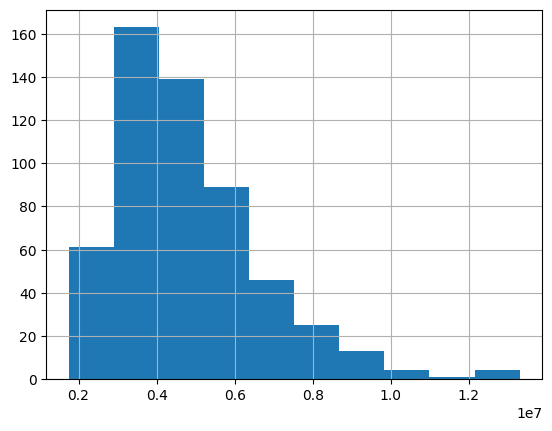

In [8]:
df['price'].hist() 

<Axes: >

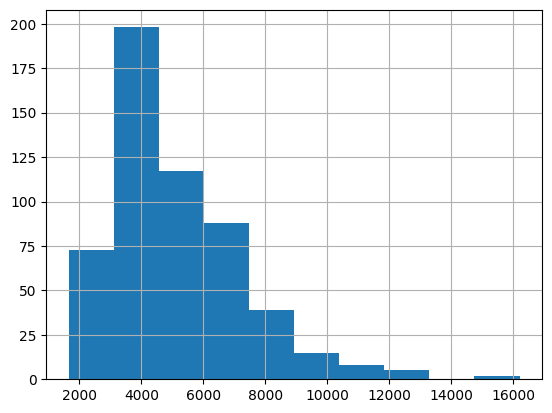

In [9]:
df['area'].hist() 

Correlation Heatmap

In [10]:
df["mainroad"].value_counts(normalize=True) 
df['furnishingstatus'].value_counts()

furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64

In [11]:
df.corr(numeric_only=True)['price'].sort_values(ascending=False)


price             1.000000
area              0.535997
bathrooms         0.517545
stories           0.420712
price_per_sqft    0.392921
parking           0.384394
bedrooms          0.366494
Name: price, dtype: float64

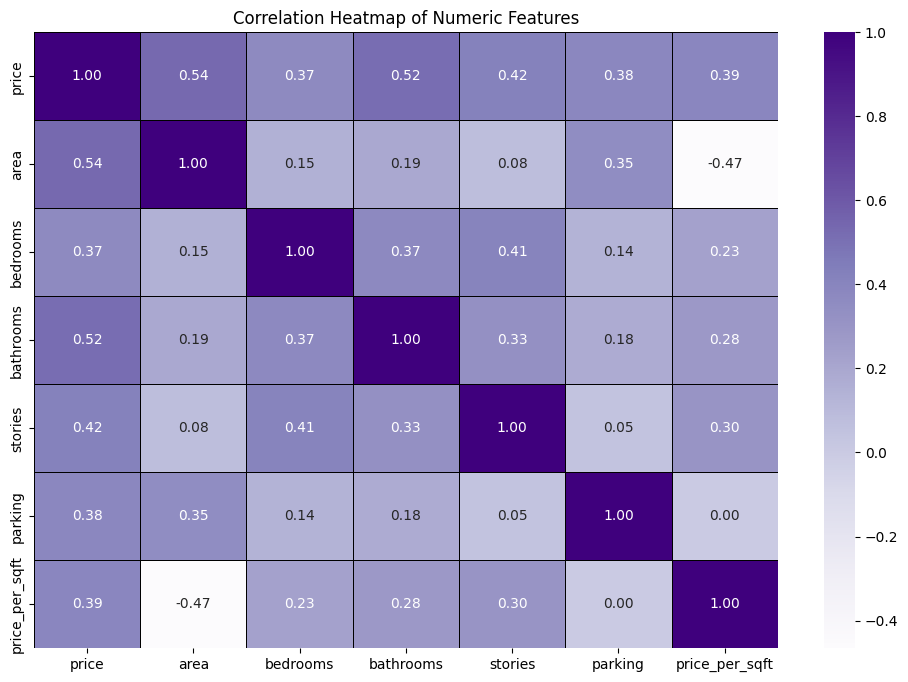

In [12]:
numeric_cols = ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'price_per_sqft']

plt.figure(figsize=(12,8))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap='Purples', linewidths=0.5, linecolor='black')
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

Models to use Linear Regression, Random Forests

In [34]:
df['furnishingstatus'].dtype


dtype('float64')

In [43]:
# Convert bool columns to int (True -> 1, False -> 0)
#binary_cols = [
    #'mainroad',
    #'guestroom',
    #'basement',
   # 'hotwaterheating',
  #  'airconditioning',
 #   'prefarea'
#]

In [44]:
# Separate features and target
X = df.drop("price", axis=1)
y = df["price"]

# Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (436, 13)
Testing Data Shape: (109, 13)


In [49]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Initialize and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluate model
print("R² Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

R² Score: 0.884008757541762
MAE: 503615.2066919669


In [47]:
y_pred[:5]


array([4148972.45330232, 6520677.74528917, 3290485.35749854,
       5692717.46942605, 2549970.53687409])

In [48]:
y_test[:5]


316    4060000
77     6650000
360    3710000
90     6440000
493    2800000
Name: price, dtype: int64

In [50]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rf = RandomForestRegressor(
    n_estimators=300,       # number of trees
    max_depth=None,        # let trees grow fully
    min_samples_leaf=5,    # controls overfitting
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)
print("MAE:", mae)
print("RMSE:", rmse)


feature_importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance)


R² Score: 0.9114921899009788
MAE: 352071.78887682845
RMSE: 668856.4446104784
area                0.537466
price_per_sqft      0.429565
bathrooms           0.018420
airconditioning     0.006964
parking             0.002503
prefarea            0.002139
basement            0.001091
stories             0.000956
bedrooms            0.000525
mainroad            0.000220
guestroom           0.000151
hotwaterheating     0.000000
furnishingstatus    0.000000
dtype: float64
